# MDPToolbox vs Marmote vs MDPSolver

Les 51 modèles du catalogue, avec leurs paramètres par défaut, et les 17 solveurs
de ces trois bibliothèques sont ajoutés explicitement, un par un.

Utiliser un noyau Python 3.11+ avec les dépendances installées depuis la racine :
```sh
python -m pip install -e ".[notebooks,mdptoolbox,marmote,mdpsolver,maze]"
```

Le benchmark vérifie la précision absolue par le résidu complet de Bellman.
Le timeout s'applique à chaque essai de solveur ; les modèles réutilisent leur
cache lorsqu'il existe. Utiliser MDPSolver 0.10.2 ou plus récent pour le correctif
VI/SOR ; les exports historiques en 0.10.1 peuvent contenir les anciennes erreurs.

In [4]:
import random

import numpy as np

from mdpforge import Benchmark

DISCOUNT = 0.99
SIZE = "medium"
PRECISION = 1e-3
REPEATS = 3
SEED = 0
TIMEOUT = 10  # Secondes par essai ; None désactive l'isolation en processus.

np.random.seed(SEED)
random.seed(SEED)

In [ ]:
bench = Benchmark(default_solvers=False)

bench.reset()
bench.add_solver(family=["vi", "mpi"], backend=["mdptoolbox", 'mdpforge'])
bench.add_mdp(category="service_operations", size=SIZE, verbose=True)
results = bench.run(
    discount=DISCOUNT,
    precision=PRECISION,
    repeats=REPEATS,
    seed=SEED,
    timeout=TIMEOUT,
    verbose=True,
)

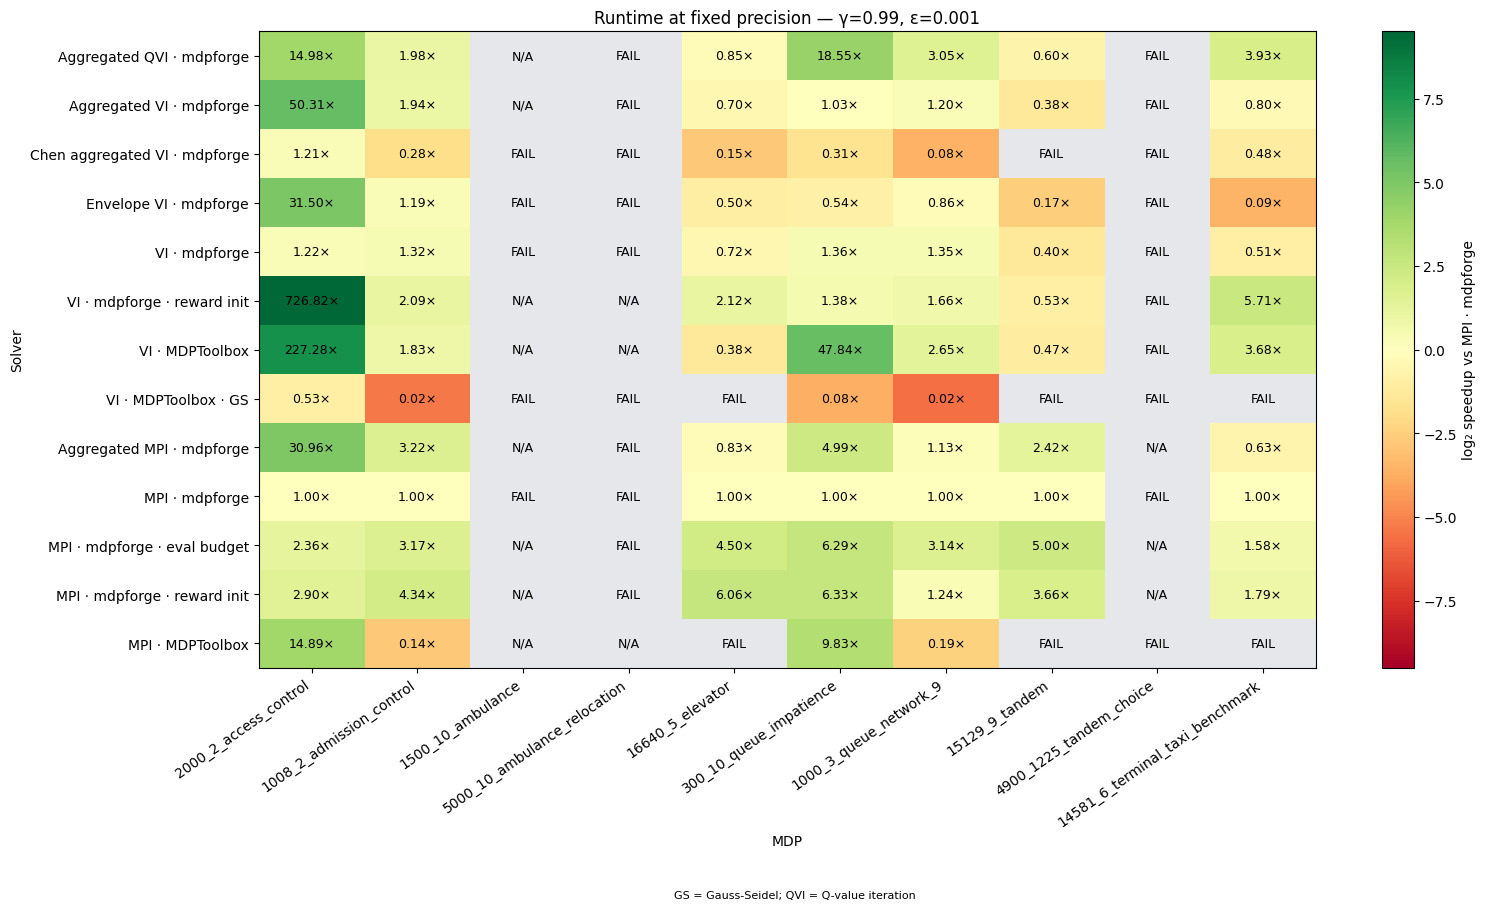

(<Figure size 1600x915 with 2 Axes>,
 <Axes: title={'center': 'Runtime at fixed precision — γ=0.99, ε=0.001'}, xlabel='MDP', ylabel='Solver'>)

In [10]:
results.plot_heat(reference='mdpforge_mpi')

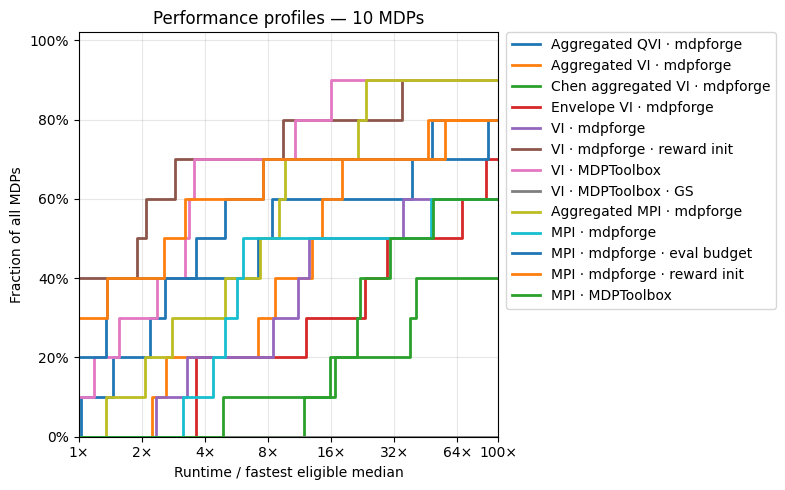

(<Figure size 800x500 with 1 Axes>,
 <Axes: title={'center': 'Performance profiles — 10 MDPs'}, xlabel='Runtime / fastest eligible median', ylabel='Fraction of all MDPs'>)

In [11]:
results.plot_performance_profile()

In [13]:
results.summary()

,model,solver,n_success,n_trials,median_runtime,complete
0,2000_2_access_control,aggregated_mpi,3,3,0.098582,True
1,2000_2_access_control,aggregated_qvi,3,3,0.203836,True
2,2000_2_access_control,aggregated_vi,3,3,0.060674,True
3,2000_2_access_control,chen_td,3,3,2.514306,True
4,2000_2_access_control,envelope_vi,3,3,0.096908,True
...,...,...,...,...,...,...
125,14581_6_terminal_taxi_benchmark,mdpforge_vi,3,3,0.523809,True
126,14581_6_terminal_taxi_benchmark,mdpforge_vi_reward_init,3,3,0.047027,True
127,14581_6_terminal_taxi_benchmark,mdptoolbox_mpi,0,3,NaN,False
128,14581_6_terminal_taxi_benchmark,mdptoolbox_vi,3,3,0.072999,True
